# 03 · Geodata with GeoPandas: geometries, CRS and maps

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/oechenique/python-gis-basics/blob/main/notebooks/03_Intro_To_Geodata.ipynb)

Points, lines and polygons with shapely; a GeoDataFrame with a CRS; a country layer from Natural Earth; a choropleth and an interactive map.
It ends with the measurement behind this repo's headline figure: **what a "5 km" buffer really measures when it is drawn in Web Mercator (EPSG:3857)** instead of the local UTM zone.

Data: 12 Argentine cities (typed in the notebook) and [Natural Earth](https://www.naturalearthdata.com/) 1:110m countries (public domain, ~200 KB, downloaded once to `data/`).

In [1]:
# On Colab only mapclassify is missing (needed by explore() and scheme=...)
try:
    import mapclassify  # noqa: F401
except ImportError:
    %pip install -q mapclassify

In [2]:
import urllib.request
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
from pyproj import Geod
from shapely.geometry import LineString, Point, Polygon

print("geopandas", gpd.__version__)

geopandas 1.2.0


## 1. Geometries: point, line, polygon

Shapely works in plain (x, y) numbers. It does not know they are degrees, so `.length` and `.area` come out in degrees.

In [3]:
buenos_aires = Point(-58.3816, -34.6037)
route = LineString([(-58.3816, -34.6037), (-60.6393, -32.9468), (-64.1888, -31.4201)])  # BA -> Rosario -> Córdoba
box = Polygon([(-59, -35), (-58, -35), (-58, -34), (-59, -34)])

print("route length:", round(route.length, 3), "(degrees, meaningless)")
print("box area:", box.area, "(square degrees, meaningless)")
print("BA inside the box?", buenos_aires.within(box))

route length: 6.664 (degrees, meaningless)
box area: 1.0 (square degrees, meaningless)
BA inside the box? True


## 2. A GeoDataFrame with a CRS

`points_from_xy(lon, lat)` plus `crs="EPSG:4326"` tells GeoPandas the numbers are WGS84 degrees, so it can reproject them.

In [4]:
# (name, province, region, latitude, longitude): 12 Argentine cities, coordinates of the city centre
CITIES = [
    ("Buenos Aires", "CABA", "Pampeana", -34.6037, -58.3816),
    ("Córdoba", "Córdoba", "Pampeana", -31.4201, -64.1888),
    ("Rosario", "Santa Fe", "Pampeana", -32.9468, -60.6393),
    ("Mar del Plata", "Buenos Aires", "Pampeana", -38.0055, -57.5426),
    ("Mendoza", "Mendoza", "Cuyo", -32.8895, -68.8458),
    ("San Miguel de Tucumán", "Tucumán", "NOA", -26.8083, -65.2176),
    ("Salta", "Salta", "NOA", -24.7821, -65.4232),
    ("Posadas", "Misiones", "NEA", -27.3671, -55.8961),
    ("Resistencia", "Chaco", "NEA", -27.4606, -58.9839),
    ("Neuquén", "Neuquén", "Patagonia", -38.9516, -68.0591),
    ("San Carlos de Bariloche", "Río Negro", "Patagonia", -41.1335, -71.3103),
    ("Ushuaia", "Tierra del Fuego", "Patagonia", -54.8019, -68.3030),
]

cities = pd.DataFrame(CITIES, columns=["city", "province", "region", "lat", "lon"])
cities = gpd.GeoDataFrame(cities, geometry=gpd.points_from_xy(cities["lon"], cities["lat"]), crs="EPSG:4326")
print(cities.crs)
cities.head(3)

EPSG:4326


,city,province,region,lat,lon,geometry
0,Buenos Aires,CABA,Pampeana,-34.6037,-58.3816,POINT (-58.3816 -34.6037)
1,Córdoba,Córdoba,Pampeana,-31.4201,-64.1888,POINT (-64.1888 -31.4201)
2,Rosario,Santa Fe,Pampeana,-32.9468,-60.6393,POINT (-60.6393 -32.9468)


## 3. Lengths in metres

The same route measured on the ellipsoid with `pyproj.Geod` (the reference) and after projecting to the UTM zone that GeoPandas suggests.

In [5]:
geod = Geod(ellps="WGS84")
route_gs = gpd.GeoSeries([route], crs="EPSG:4326")
utm = route_gs.estimate_utm_crs()

print(f"geodesic (WGS84 ellipsoid): {geod.geometry_length(route) / 1000:7.1f} km")
print(f"projected to {utm.name}: {route_gs.to_crs(utm).length.iloc[0] / 1000:7.1f} km")

geodesic (WGS84 ellipsoid):   653.5 km
projected to WGS 84 / UTM zone 20S:   653.6 km


## 4. Reading a real layer: Natural Earth countries

Downloaded once to `data/` (ignored by git) and read with `gpd.read_file`, which opens the zipped shapefile directly.

In [6]:
NE_URL = "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip"
ne_path = Path("data") / "ne_110m_admin_0_countries.zip"
ne_path.parent.mkdir(exist_ok=True)
if not ne_path.exists():
    req = urllib.request.Request(NE_URL, headers={"User-Agent": "python-gis-basics (github.com/oechenique)"})
    ne_path.write_bytes(urllib.request.urlopen(req, timeout=60).read())

countries = gpd.read_file(ne_path)
south_america = countries[countries["CONTINENT"] == "South America"][["NAME", "ISO_A3", "POP_EST", "geometry"]].copy()
print(len(south_america), "countries, CRS", south_america.crs)

13 countries, CRS EPSG:4326


## 5. Areas need an equal-area CRS, then a choropleth

Population density = population / area. The area is computed in a South America Albers equal-area projection (`ESRI:102033`), never in degrees.

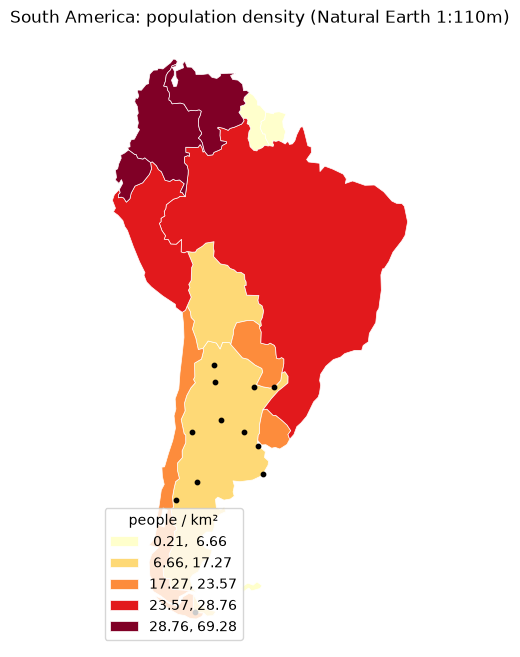

,NAME,area_km2,density
44,Ecuador,250775.7,69.3
32,Colombia,1151968.3,43.7
40,Venezuela,908434.8,31.4
31,Peru,1309795.6,24.8
29,Brazil,8508103.2,24.8


In [7]:
south_america["area_km2"] = south_america.to_crs("ESRI:102033").area / 1e6
south_america["density"] = south_america["POP_EST"] / south_america["area_km2"]

fig, ax = plt.subplots(figsize=(6, 8))
south_america.plot(column="density", scheme="quantiles", k=5, cmap="YlOrRd", edgecolor="white",
                   linewidth=0.5, legend=True, legend_kwds={"title": "people / km²", "loc": "lower left"}, ax=ax)
cities.plot(ax=ax, color="black", markersize=10)
ax.set_title("South America: population density (Natural Earth 1:110m)")
ax.set_axis_off()
plt.show()

south_america.sort_values("density", ascending=False)[["NAME", "area_km2", "density"]].round(1).head(5)

## 6. Spatial join and an interactive map

Which country each city falls in (`sjoin`), then `explore()` for a Leaflet map.

In [8]:
joined = gpd.sjoin(cities, south_america[["NAME", "geometry"]], how="left", predicate="within")
print(joined["NAME"].value_counts(dropna=False).to_string())

m = south_america.explore(column="density", scheme="quantiles", k=5, cmap="YlOrRd", tooltip=["NAME", "density"], name="countries")
cities.explore(m=m, color="black", tooltip=["city", "region"], name="cities")
m

NAME
Argentina    10
NaN           1
Paraguay      1


Two of the 12 cities land in the wrong place, and that is the lesson: at 1:110m the borders are heavily simplified. **Posadas** sits on the Paraná river, the border with Paraguay, and falls on the Paraguayan side; **Mar del Plata** is on the coast and falls in the sea (no country). Use the 1:10m layer (or official boundaries) whenever a join depends on borders or coastlines.

## 7. Degrees vs metres: the 5 km buffer

The old version of this notebook drew "5 km" study areas in **EPSG:3857** (Web Mercator), the CRS of web maps. Mercator stretches distances by `1 / cos(latitude)`, so 5,000 Mercator metres are fewer real metres the further you are from the equator.

Here the same buffer is drawn two ways for Buenos Aires and Ushuaia: in EPSG:3857 and in the city's own UTM zone (`estimate_utm_crs()`: 21S for Buenos Aires, 19S for Ushuaia). Both polygons are then brought back to WGS84 and their **true area is measured on the ellipsoid** with `pyproj.Geod`. A 5 km circle should have π · 5² ≈ 78.5 km².

In [9]:
import math

RADIUS_M = 5_000
EXPECTED_KM2 = math.pi * (RADIUS_M / 1000) ** 2

rows, shapes = [], {}
for name in ["Buenos Aires", "Ushuaia"]:
    pt = cities[cities["city"] == name][["city", "geometry"]]
    utm_crs = pt.estimate_utm_crs()
    buffers = {
        "EPSG:3857": pt.to_crs("EPSG:3857").buffer(RADIUS_M).to_crs("EPSG:4326").iloc[0],
        utm_crs.name: pt.to_crs(utm_crs).buffer(RADIUS_M).to_crs("EPSG:4326").iloc[0],
    }
    shapes[name] = (utm_crs, buffers)
    for crs_name, poly in buffers.items():
        area_km2 = abs(geod.geometry_area_perimeter(poly)[0]) / 1e6
        rows.append({
            "city": name,
            "lat": round(pt.geometry.y.iloc[0], 2),
            "buffer drawn in": crs_name,
            "true area (km²)": round(area_km2, 1),
            "equivalent radius (km)": round(math.sqrt(area_km2 / math.pi), 2),
            "error vs 78.5 km²": f"{area_km2 / EXPECTED_KM2 - 1:+.0%}",
        })

assert shapes["Buenos Aires"][0].to_epsg() == 32721 and shapes["Ushuaia"][0].to_epsg() == 32719
buffer_table = pd.DataFrame(rows)
buffer_table

,city,lat,buffer drawn in,true area (km²),equivalent radius (km),error vs 78.5 km²
0,Buenos Aires,-34.6,EPSG:3857,53.0,4.11,-33%
1,Buenos Aires,-34.6,WGS 84 / UTM zone 21S,78.4,5.00,-0%
2,Ushuaia,-54.8,EPSG:3857,26.1,2.88,-67%
3,Ushuaia,-54.8,WGS 84 / UTM zone 19S,78.5,5.00,-0%


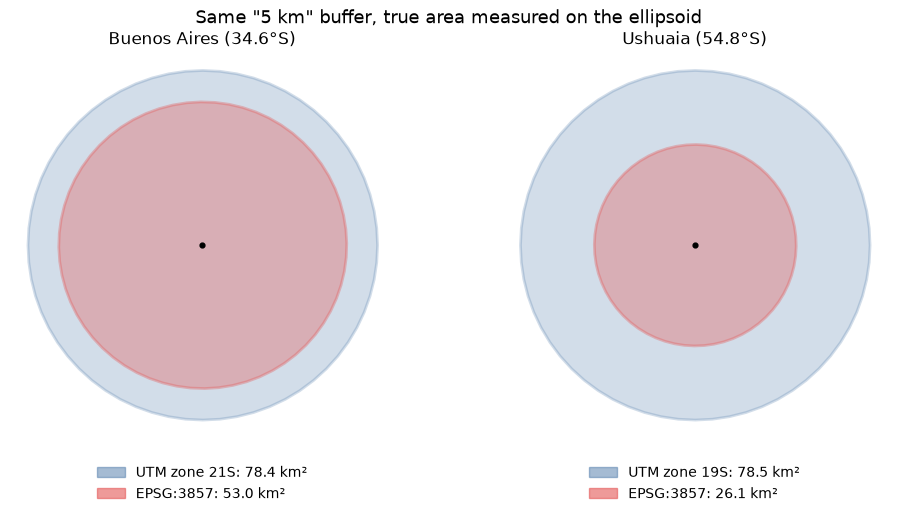

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, (name, (utm_crs, buffers)) in zip(axes, shapes.items()):
    (mercator, utm_poly) = buffers.values()
    gpd.GeoSeries([utm_poly], crs="EPSG:4326").to_crs(utm_crs).plot(ax=ax, facecolor="#4c78a8", alpha=0.25, edgecolor="#4c78a8", linewidth=2)
    gpd.GeoSeries([mercator], crs="EPSG:4326").to_crs(utm_crs).plot(ax=ax, facecolor="#e45756", alpha=0.35, edgecolor="#e45756", linewidth=2)
    cities[cities["city"] == name].to_crs(utm_crs).plot(ax=ax, color="black", markersize=12)
    r = buffer_table[(buffer_table["city"] == name)].set_index("buffer drawn in")
    ax.set_title(f"{name} ({abs(r['lat'].iloc[0]):.1f}°S)", fontsize=12)
    ax.legend(handles=[
        plt.Rectangle((0, 0), 1, 1, color="#4c78a8", alpha=0.5, label=f"{utm_crs.name.split('/')[-1].strip()}: {r.loc[utm_crs.name, 'true area (km²)']} km²"),
        plt.Rectangle((0, 0), 1, 1, color="#e45756", alpha=0.6, label=f"EPSG:3857: {r.loc['EPSG:3857', 'true area (km²)']} km²"),
    ], loc="lower center", bbox_to_anchor=(0.5, -0.2), frameon=False, fontsize=10)
    ax.set_axis_off()
fig.suptitle("Same \"5 km\" buffer, true area measured on the ellipsoid", fontsize=13)
fig.tight_layout()

img_dir = Path("../docs/img")
out = img_dir / "buffers_3857_vs_utm.png" if img_dir.exists() else Path("buffers_3857_vs_utm.png")
fig.savefig(out, dpi=110, bbox_inches="tight", facecolor="white")
plt.show()

## Takeaways

- A GeoDataFrame needs a CRS; lengths and areas only mean something in a projected or equal-area CRS (or on the ellipsoid with `pyproj.Geod`).
- **Web Mercator is for drawing tiles, not for measuring.** The table above shows how much a "5 km" buffer in EPSG:3857 shrinks in Buenos Aires and, much more, in Ushuaia.
- `estimate_utm_crs()` picks the right UTM zone per place (21S for Buenos Aires, 19S for Ushuaia). For a whole country use an equal-area projection, as in section 5.

## Exercises

1. Repeat the buffer table for Salta (24.8°S). Is the error closer to Buenos Aires or to the equator?
2. Count how many of the 12 cities are within 700 km of Buenos Aires (buffer in UTM 21S + `sjoin`).
3. Color the cities by `region` in `explore()`.

## Resources

[GeoPandas user guide](https://geopandas.org/en/stable/docs/user_guide.html) · [Shapely](https://shapely.readthedocs.io/) · [pyproj Geod](https://pyproj4.github.io/pyproj/stable/api/geod.html) · [Natural Earth](https://www.naturalearthdata.com/)